<a href="https://colab.research.google.com/github/novalrnv/244107020210-mobile-course/blob/main/week-9/Modul09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Modul 9 - Morfologi

Mata Kuliah : Pengolahan Citra dan Visi Komputer

Nama : **Khoirul Umam Novalidi**

NIM : **Khoirul Umam Novalidi**

Isi notebook mengikuti langkah praktikum Modul 9: erosi, dilasi, opening, closing,
top-hat, bottom-hat (black-hat), skeleton, dan thickening.

Citra yang dipakai: `plat nomer.jpg`, `j.png`, `kitten01.jpg`, `lily.jpg`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Mount Google Drive

Menghubungkan Colab dengan Drive, lalu notebook di-rename menjadi `Week9.ipynb`
pada repository yang dipakai minggu lalu. Kalau dijalankan lokal, mount dilewati.

In [ ]:
try:
    from google.colab import drive

    drive.mount('/content/drive')
    IN_COLAB = True
except Exception as e:
    print('bukan di Colab ->', e)
    IN_COLAB = False

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Import library

`cv2` untuk operasi morfologi, `numpy` untuk array dan pembuatan structuring element
manual, `matplotlib` untuk menampilkan citra.

In [ ]:
import os

import cv2
import numpy as np
from matplotlib import pyplot as plt

%matplotlib inline

print('OpenCV :', cv2.__version__)
print('NumPy  :', np.__version__)

OpenCV : 5.0.0
NumPy  : 2.1.3


### Lokasi citra

Di modul, citra dibaca dari `/content/drive/MyDrive/PCVK/Images/...`.
Supaya notebook juga jalan di lokal, path dicari dulu lewat helper `img_path()`.

In [ ]:
IMG_DIR = '/content/drive/MyDrive/PCVK/Images'
_CWD = os.getcwd()
_CARI = [IMG_DIR,
         '/content/drive/MyDrive/Matkul Sem 5/PCVK/Images',
         _CWD,
         os.path.join(_CWD, 'Images')]

def img_path(nama):
    for folder in _CARI:
        path = os.path.join(folder, nama)
        if os.path.exists(path):
            return path
    return os.path.join(IMG_DIR, nama)  # biar pesan error-nya jelas di Colab

for nama in ['plat nomer.jpg', 'j.png', 'kitten01.jpg', 'lily.jpg']:
    print(nama, '->', img_path(nama))

plat nomer.jpg -> /content/drive/MyDrive/Matkul Sem 5/PCVK/Images/plat nomer.jpg
j.png -> /content/drive/MyDrive/Matkul Sem 5/PCVK/Images/j.png
kitten01.jpg -> /content/drive/MyDrive/Matkul Sem 5/PCVK/Images/kitten01.jpg
lily.jpg -> /content/drive/MyDrive/Matkul Sem 5/PCVK/Images/lily.jpg


## 3. Fungsi dilasi tanpa library (SED cross 3 x 3)

Dilasi tanpa `cv2.dilate`. Structuring element digeser ke seluruh piksel citra;
hasil di piksel tengah = nilai maksimum dari `temp * SED`. Karena SED bernilai 1
di area cross, piksel objek menyebar ke arah cross saja. Citra di-threshold dulu
(125 / 200) supaya jadi biner, lalu dipakai `w = 5`.

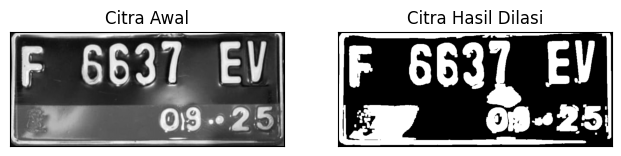

In [ ]:
# Dilasi tanpa library
def dilasi_citra(F, w):
    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

path = img_path('plat nomer.jpg')
img_d = cv2.imread(path, 0)

if img_d is None:
    print(f"Error: Gambar tidak ditemukan di path: {path}")
    print("Silakan periksa apakah file 'plat nomer.jpg' sudah diunggah ke Google Drive Anda.")
else:
    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)

    w = 5
    imgD = dilasi_citra(thresh, w)

    plt.figure(figsize=(12, 4))
    plt.subplot(131), plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

## 4. Dilasi dengan library OpenCV (SED cross 3 x 3)

Operasi yang sama dikerjakan `cv2.dilate` dengan kernel `np.ones((3, 3))`
dan satu iterasi. Hasilnya objek putih jadi lebih tebal/lebar.

Kernel:
 [[1 1 1]
 [1 1 1]
 [1 1 1]]


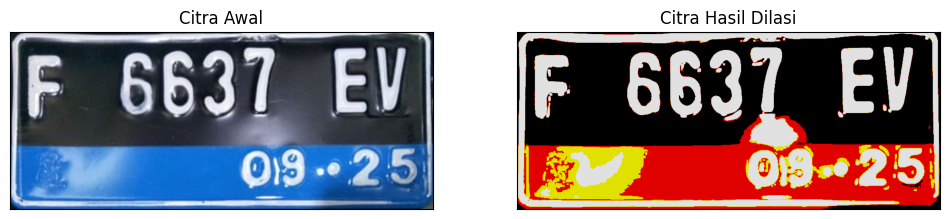

In [ ]:
path = img_path('plat nomer.jpg')
img = cv2.imread(path)

if img is None:
    print(f"Error: Gambar tidak ditemukan di path: {path}")
    print("Silakan pastikan file 'plat nomer.jpg' sudah diunggah ke Google Drive Anda pada folder yang sesuai.")
else:
    # img = cv2.imread('morp.jpg', 0)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3, 3), np.uint8) # Menggunakan uint8 karena merupakan tipe standar untuk kernel morfologi OpenCV
    dilasi = cv2.dilate(thresh, kernel, iterations=1)
    print("Kernel:\n", kernel)

    plt.figure(figsize=(12, 4))
    plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(dilasi), plt.title('Citra Hasil Dilasi')
    plt.xticks([]), plt.yticks([])
    plt.show()

## 5. Fungsi erosi tanpa library (SE square 5 x 5)

Kebalikan dilasi: nilai piksel hasil = minimum dari `temp * SE`. Piksel tepi objek
hilang, jadi objek menyusut. Citra di-threshold 175 / 225, `k = 5`.

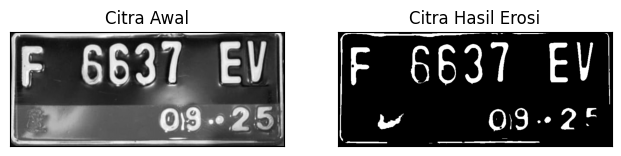

In [ ]:
# Erosi Tanpa Library
def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

img_e = cv2.imread(img_path('plat nomer.jpg'), 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

## 6. Erosi dengan library OpenCV (SE square 5 x 5)

`cv2.erode` dengan kernel 5 x 5, satu iterasi. Garis tipis dan noise kecil hilang,
huruf pada plat jadi lebih tipis.

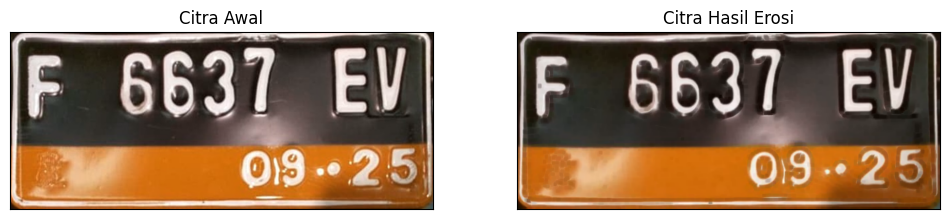

In [ ]:
# EROSI LIBRARY
img = cv2.imread(img_path('plat nomer.jpg'))

kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.figure(figsize=(12, 4))
plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(erosion), plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

## 7. Opening (SE square 3 x 3)

Opening = erosi lalu dilasi. Bagian pertama memakai fungsi manual
(`dilasi_citra(erosi_citra(...))`, k = 7), bagian kedua memakai
`cv2.morphologyEx(..., MORPH_OPEN, ...)` dengan kernel 3 x 3.

### 7a. Opening tanpa library morphology

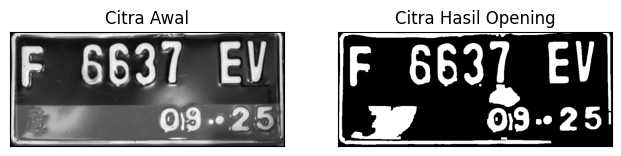

In [ ]:
img_o = cv2.imread(img_path('plat nomer.jpg'), 0)
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

### 7b. Opening dengan library morphology

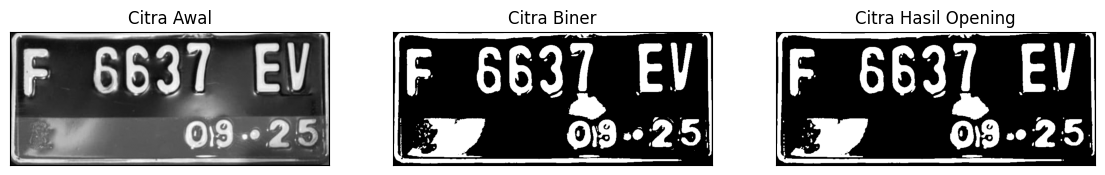

In [ ]:
# Dengan Menggunakan Library
img = cv2.imread(img_path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.show()

## 8. Closing (SE square 3 x 3)

Closing = dilasi lalu erosi. Versi manual memakai `erosi_citra(dilasi_citra(...))`
dengan k = 7, versi library memakai `MORPH_CLOSE` dengan kernel 3 x 3.
Lubang kecil di dalam objek tertutup.

### 8a. Closing tanpa library morphology

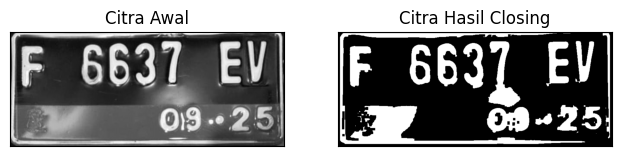

In [ ]:
img_c = cv2.imread(img_path('plat nomer.jpg'), 0)
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k = 7
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

### 8b. Closing dengan library morphology

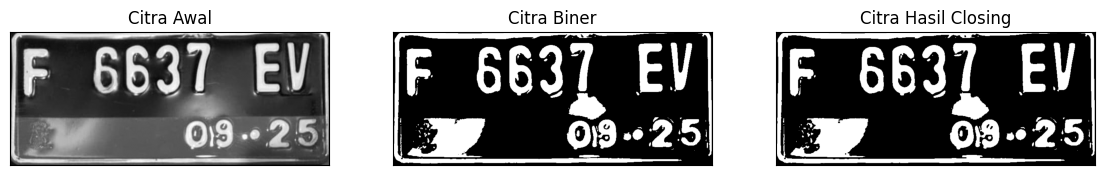

In [ ]:
img = cv2.imread(img_path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])

plt.show()

## 9. Dilasi dengan SED cross 3 x 3 dan 5 x 5

SED diisi manual sebagai array cross (`0 1 0 / 1 1 1 / 0 1 0` untuk 3 x 3,
versi 5 x 5 dengan batang lebih panjang). Objek melebar hanya ke arah vertikal
dan horizontal.

### 9a. Cross 3 x 3

SED = Cross 3


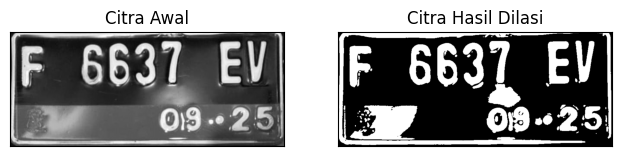

In [ ]:
# Dilasi Cross SED
def dilasi_citra(F, w):
    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    # SED = np.ones((w, w), dtype=np.uint8)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 3')
img_d = cv2.imread(img_path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

### 9b. Cross 5 x 5

SED = Cross 5


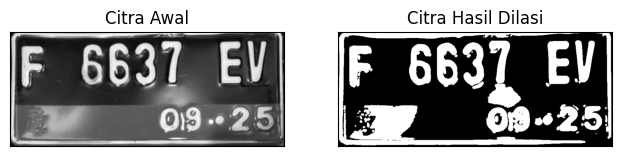

In [ ]:
def dilasi_citra(F, w):
    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    # SED = np.ones((w, w), dtype=np.uint8)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 5')
img_d = cv2.imread(img_path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

## 10. Dilasi dengan SED circular 3 x 3 dan 5 x 5

SED dibuat dengan `cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))`,
jadi penyebaran objek mengikuti bentuk lingkaran.

### 10a. Circle 3 x 3

SED = Circle 3


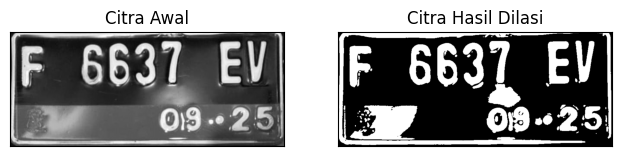

In [ ]:
# Dilasi Circular SED
def dilasi_citra(F, w):
    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Circle 3')
img_d = cv2.imread(img_path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

### 10b. Circle 5 x 5

SED = Circle 5


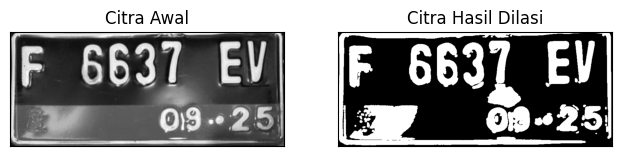

In [ ]:
print('SED = Circle 5')
img_d = cv2.imread(img_path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

## 11. Erosi dengan SE rectangle 3 x 5 dan 5 x 7

SE persegi panjang dari `cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))`.
Parameter `p` = tinggi, `l` = lebar; dua loop memakai offset berbeda
(`constant1` dari `l`, `constant2` dari `p`) supaya jendela tetap sesuai ukuran SE.

### 11a. Rectangle 3 x 5

SE = Rectangle 3x5


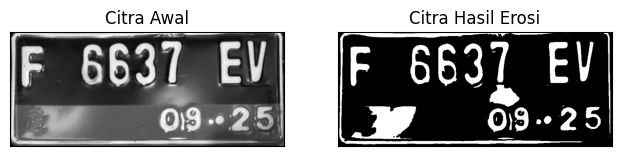

In [ ]:
# Erosi Rectangle SE
def erosi_citra(F, p, l):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))  # SE persegi panjang
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    # print(SE)
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1:i + constant1 + 1, j - constant2:j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

print('SE = Rectangle 3x5')
img_e = cv2.imread(img_path('plat nomer.jpg'), 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 5
l = 3
imgE = erosi_citra(thresh1, p, l)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

### 11b. Rectangle 5 x 7

SE = Rectangle 5x7


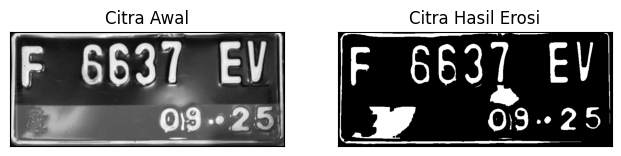

In [ ]:
print('SE = Rectangle 5x7')
img_e = cv2.imread(img_path('plat nomer.jpg'), 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 7
l = 5
imgE = erosi_citra(thresh1, p, l)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

## 12. Erosi dengan SE line vertikal 3 dan 5

Sesuai perintah modul, langkah ini memakai citra `j.png` (bukan `plat nomer.jpg`
seperti pada potongan kode). SE dibuat dengan
`cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))`, jadi hanya arah vertikal
yang mengikis objek.

### 12a. Line vertikal 3

SE = Line Vertikal 3


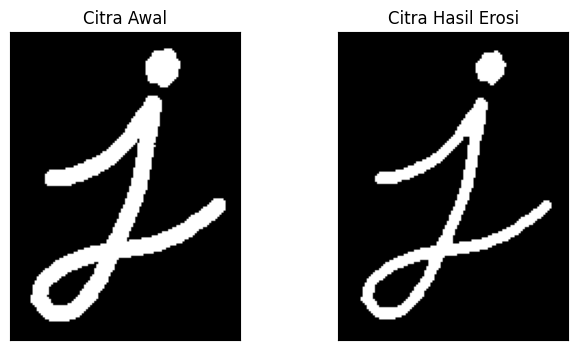

In [ ]:
# Erosi Line Vertikal SE
def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))  # SE line vertikal
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

print('SE = Line Vertikal 3')
img_e = cv2.imread(img_path('j.png'), 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 3
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

### 12b. Line vertikal 5

SE = Line Vertikal 5


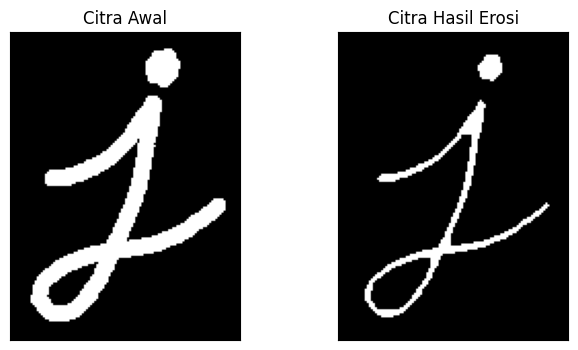

In [ ]:
print('SE = Line Vertikal 5')
img_e = cv2.imread(img_path('j.png'), 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

## 13. Top-hat

Top-hat = citra asli - opening(citra). Yang tersisa adalah fitur terang yang
ukurannya lebih kecil dari SE. SE yang dipakai rectangle 3 x 3.

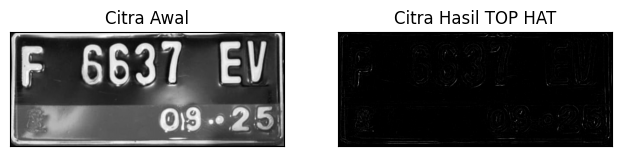

In [ ]:
# Getting the kernel to be used in Top-Hat
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread(img_path('plat nomer.jpg'))
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

# cv2.imshow("original", input_image)
# cv2.imshow("tophat", tophat_img)
# cv2.waitKey(5000)
plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

## 14. Black-hat (bottom-hat)

Black-hat = closing(citra) - citra asli, sehingga yang tampak adalah fitur gelap
yang lebih kecil dari SE. Di sini dipakai citra `kitten01.jpg` dan kernel
rectangle 13 x 5.

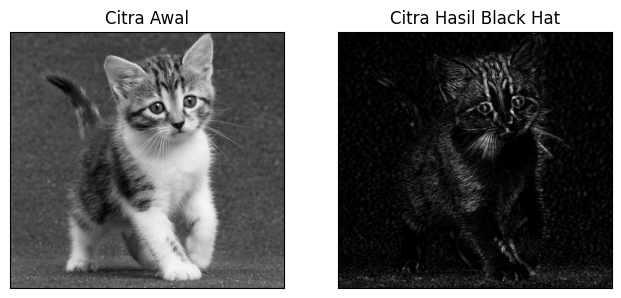

In [ ]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread(img_path('kitten01.jpg'))
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Black-Hat operation
# tophat_img = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))

blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)
# cv2.imshow("original", input_image)
# cv2.imshow("tophat", tophat_img)
# cv2.waitKey(5000)
plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

## 15. Skeleton

Citra `lily.jpg` dibinerkan dengan threshold triangle dari `skimage.filters`,
lalu `skeletonize` menyusutkan objek menjadi kerangka satu piksel.

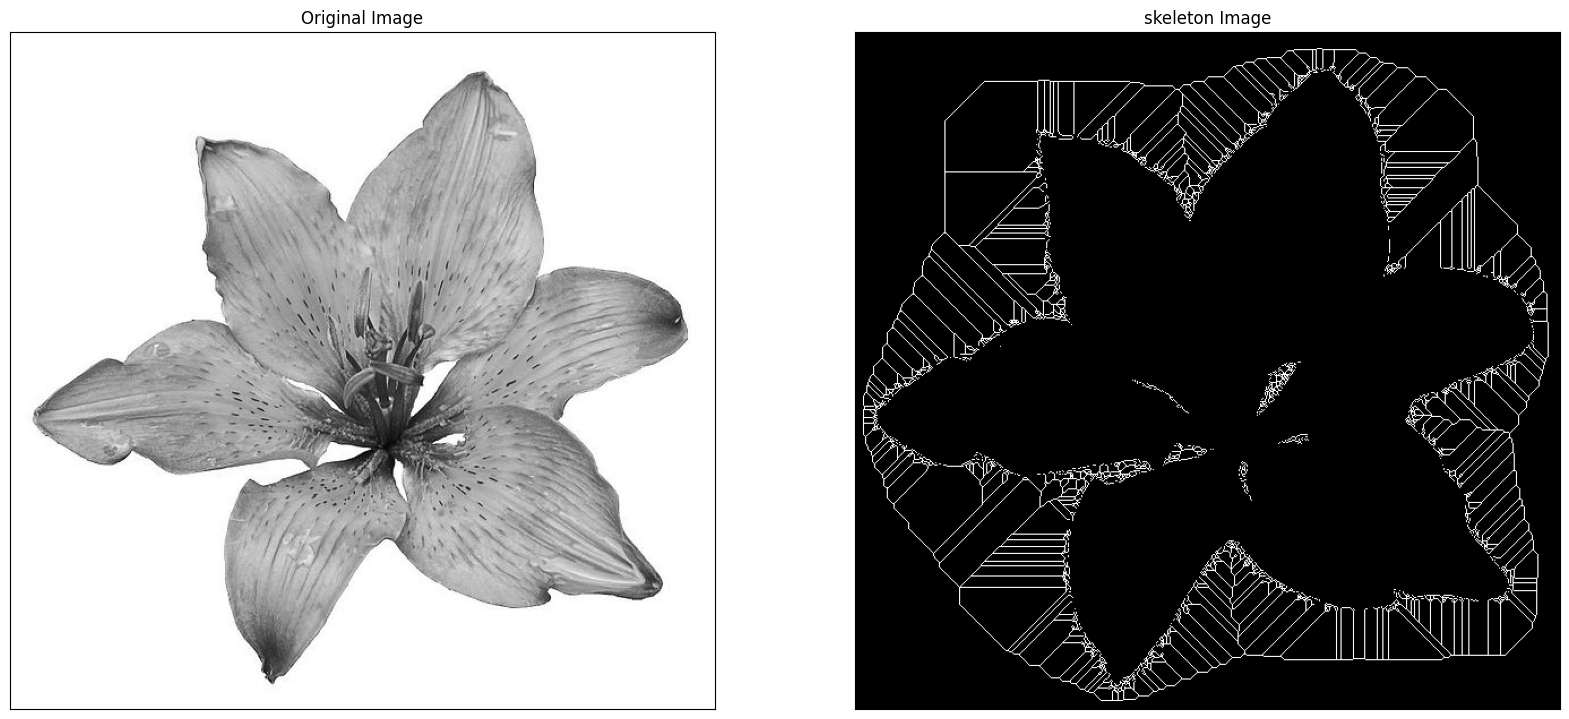

In [ ]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = cv.imread(img_path('lily.jpg'), 0)

binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20, 20))

plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])

plt.savefig('binary and bin_skeleton.png')
plt.show()

## 16. Skeleton inverse

Sama seperti langkah 15, tetapi objek yang dijadikan foreground adalah bagian
gelap (`img < threshold`), sehingga kerangka mengikuti pola gelap citra.

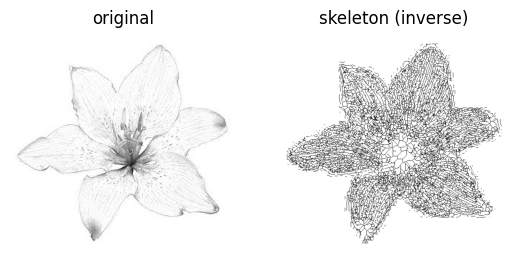

In [ ]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = io.imread(img_path('lily.jpg'))[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)

ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()

plt.show()

## 17. Thickening / thinning

Citra `lily.jpg` diubah ke grayscale float lalu dibinerkan dengan ambang 0.5.
`morphology.skeletonize` menghasilkan kerangka, sedangkan `morphology.thin`
menipiskan objek tanpa harus memutus konektivitasnya.

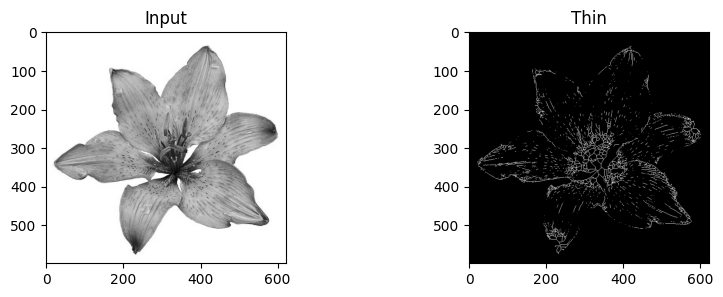

In [ ]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread(img_path('lily.jpg'))))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()

## Kesimpulan

- Erosi (`min` dari `temp * SE`) menyusutkan objek dan menghilangkan noise kecil;
  dilasi (`max` dari `temp * SED`) menebalkan objek dan menutup celah.
- Opening (erosi lalu dilasi) membuang objek kecil di luar objek utama, closing
  (dilasi lalu erosi) menutup lubang kecil di dalam objek.
- Bentuk SE menentukan arah perubahan: cross melebar ke 4 arah, ellipse/circle
  melebar melingkar, rectangle dan line vertikal menyusut/menebal satu arah saja.
- Top-hat menyisakan fitur terang yang lebih kecil dari SE, black-hat menyisakan
  fitur gelap yang lebih kecil dari SE.
- Skeleton dan thin mereduksi objek menjadi kerangka tipis tanpa mengubah
  topologi bentuk aslinya.